loading the data and add German local time. 



In [5]:
import pandas as pd 

df = pd.read_parquet("../data/raw/prices.parquet")
df = df.dropna(subset=["price_euro_mwh"])       #Dropping the future hours in this notebook only
df["ts_local"] = df["ts_utc"].dt.tz_convert("Europe/Berlin")
df["year"] = df["ts_utc"].dt.year
df["month"] = df["ts_utc"].dt.month
df["weekday"] = df["ts_utc"].dt.day_of_week   # 0 = Monday ... 6 = Sunday
df["hour"] = df["ts_utc"].dt.hour
df["negative"] = df["price_euro_mwh"] < 0
df.head()

,ts_utc,price_euro_mwh,ts_local,year,month,weekday,hour,negative
0,2018-09-30 22:00:00+00:00,59.53,2018-10-01 00:00:00+02:00,2018,9,6,22,False
1,2018-09-30 23:00:00+00:00,56.10,2018-10-01 01:00:00+02:00,2018,9,6,23,False
2,2018-10-01 00:00:00+00:00,51.41,2018-10-01 02:00:00+02:00,2018,10,0,0,False
3,2018-10-01 01:00:00+00:00,47.38,2018-10-01 03:00:00+02:00,2018,10,0,1,False
4,2018-10-01 02:00:00+00:00,47.59,2018-10-01 04:00:00+02:00,2018,10,0,2,False


- dropna removes rows with no price. This only changes the table inside the notebook. The raw file on disk stays untouched.
- tz_convert("Europe/Berlin") turns UTC into German clock time, with summer/winter time handled automatically. We need this because -“14:00 on a Sunday” only makes sense in local time.
- .dt.year, .dt.hour and so on pull one piece out of each date, like reading only the hour off a clock.
- negative is a True/False column: True when the price was below zero.
- Next Step -  are negative hours becoming more common?

In [6]:
per_year = df.groupby("year")["negative"].agg(["sum","mean","count"])
per_year["share_pct"] = (per_year["mean"] * 100).round(1)
per_year

,sum,mean,count,share_pct
year,,,,
2018,27,0.012217,2210,1.2
2019,211,0.024087,8760,2.4
2020,298,0.033925,8784,3.4
2021,139,0.015868,8760,1.6
2022,70,0.007991,8760,0.8
2023,300,0.034247,8760,3.4
2024,457,0.052026,8784,5.2
2025,573,0.065411,8760,6.5
2026,462,0.063962,7223,6.4


- groupby("year") splits the table into one group per year.
- sum counts the negative hours (Python counts True as 1, False as 0).
- mean gives the share of negative hours: the average of 1s and 0s is the fraction of 1s.
- count is how many hours each year has.
- share_pct stands for “share in percent”: what percentage of that year’s hours had a negative price.
So we read the row as in 2018 sum 27, mean 0.012217, count 2210 and share_pct 1.2 is 27 of the years 2210 hours were negative, which is 1.2%

- Watch out: 2018 only has 3 months and 2026 only has 10. Their counts aren’t fair to compare with full years, but the share is. That’s why we use the share for the chart:

Findings 
- Reading our table 
The big trend: negative hours went from 2.4% in 2019 to 6.5% in 2025, almost three times as many. In 2025 that’s 573 hours, about 24 full days’ worth of hours where power cost less than nothing.
- The dip in 2021–2022: the share fell to 1.6% and then 0.8%, the lowest of all years. That matches the energy crisis: when gas was extremely expensive, prices were pushed up everywhere, so they rarely dropped below zero.
- The fast rise from 2023: 3.4% → 5.2% → 6.5%. with some likely reason, no idea yet
- 2026 so far: 6.4%. That’s the same level as 2025, but careful: November and December are missing, and winter months have few negative hours (the sun is weak). So the full-year share will probably end a bit lower than 6.4%. Partial years can mislead in both directions.
- 2020 at 3.4%: higher than 2019 and 2021. Possibly COVID (lower demand), a rough idea 

<Axes: title={'center': 'Share of negative-price hours by hour of the day(%)'}, xlabel='hour'>

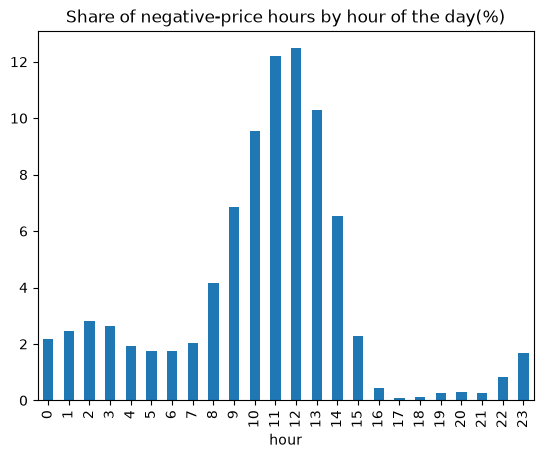

In [ ]:
(df.groupby("hour")["negative"].mean() * 100).plot(
    kind = "bar", title="Share of negative-price hours by hour of the day(%)" #to see at which hours of the day we have negative prices?
) 

What the chart shows (and what it doesn’t)

The chart does not show how much electricity people use. It shows only one thing:

For each hour of the clock: in what percentage of days was the price below zero at that hour?

Take the tallest bar, hour 12 (12:00–13:00), at about 12.5%. The bar at hour 18 is almost zero: at 18:00, the price was almost never negative.

So: high bar = price often negative at that hour.
### Findings
- Negative prices follow the sun: they are most common around midday,
  peaking at 12:00–13:00 German time (about 12.5% of those hours).
- They almost never happen in the evening (17:00–21:00, about 0.1%):
  people use more power at home while solar fades.
- Small bump at night (0:00–3:00, about 2–3%): low use while wind keeps
  producing.
- Most EV owners plug in around 17:00–19:00, exactly the worst window.
  Shifting charging to midday or night is where savings come from.

<Axes: title={'center': 'Share of negative-price hours by weekday (%) — 0 = Monday'}, xlabel='weekday'>

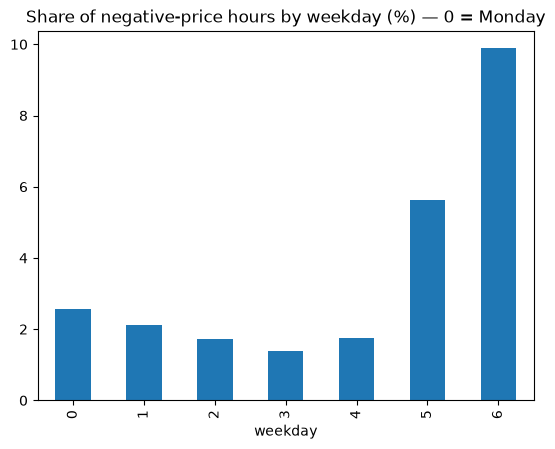

In [10]:
(df.groupby("weekday")["negative"].mean() * 100).plot(
    kind="bar", title="Share of negative-price hours by weekday (%) — 0 = Monday" #Same but weekday
)

### Findings: weekday
- Negative prices are mostly a weekend thing: Sunday about 9.9% of hours,
  Saturday about 5.6%, weekdays only about 1.4–2.6%.
- Reason: low use when businesses are closed, while sun and wind keep producing.



<Axes: title={'center': 'Share of negative-price hours by month (%)'}, xlabel='month'>

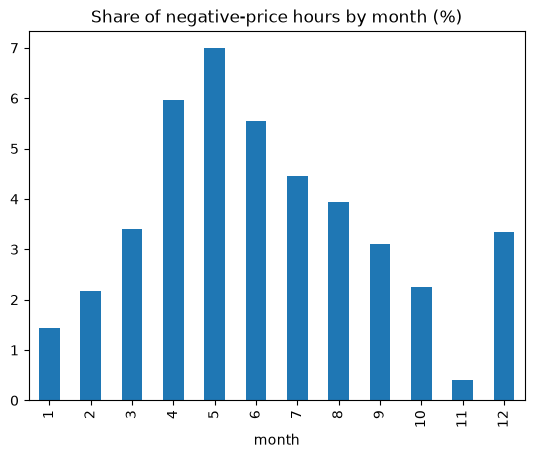

In [11]:
(df.groupby("month")["negative"].mean() * 100).plot(
    kind="bar", title="Share of negative-price hours by month (%)" #month
)

### Findings: month
- Peak in spring: May about 7%, April about 6%. Lowest in November (about 0.4%).
- Spring combines strong sun, no heat, and many public holidays (1 May,
  Ascension, Whit Monday) and we saw our second-lowest price ever was on 1 May! (2026-05-01)
- December is surprisingly high (about 3.3%) for the darkest month, probably
  Christmas holidays plus winter wind. To check later with wind data.
- Next lets zoom into one summer week


<Axes: title={'center': 'One week in June 2025'}, xlabel='ts_local'>

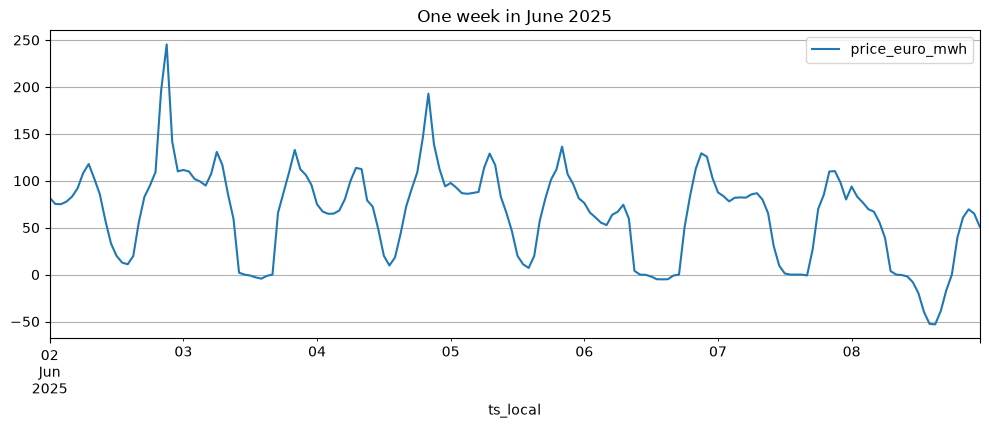

In [15]:
start = pd.Timestamp("2025-06-02", tz="Europe/Berlin")  # a monday, randomly checked in my phone. 
end = start + pd.Timedelta(days=7)
week = df[(df["ts_local"] >= start) & (df["ts_local"] < end)]
week.plot(x="ts_local", y="price_euro_mwh", figsize=(12,4),
          title="One week in June 2025",grid=True)

### Findings: one week in June 2025 (2–8 June)
- Every day has the same "duck curve": low prices around midday (solar),
  a morning peak at 07:00 and a bigger evening peak around 20:00–21:00.
- Morning peak always at 07:00 German time: 114–129 €/MWh Monday to
  Thursday, lower on Friday (74) and Saturday (87), and almost none on
  Whit Sunday (3.71).
- Sunday 8 June (Whit Sunday) had the lowest price of the week:
  ___ €/MWh at ___ German time.
- The gap between the cheapest and most expensive hour was more than
  100 €/MWh every day, from 111 (Saturday) to 234 (Monday), about
  154 €/MWh on average (15 cents per kWh). This is where EV-charging
  savings come from.

In [16]:
week = week.copy()
week["date"] = week["ts_local"].dt.date

morning = week[week["hour"].between(5, 10)]
peaks = morning.loc[morning.groupby("date")["price_euro_mwh"].idxmax()]
peaks[["ts_local", "price_euro_mwh"]]

,ts_local,price_euro_mwh
58471,2025-06-02 07:00:00+02:00,117.90
58495,2025-06-03 07:00:00+02:00,116.85
58519,2025-06-04 07:00:00+02:00,113.74
58543,2025-06-05 07:00:00+02:00,129.03
58567,2025-06-06 07:00:00+02:00,74.43
58591,2025-06-07 07:00:00+02:00,86.74
58615,2025-06-08 07:00:00+02:00,3.71


What it does:

- week.copy() makes a separate copy, so pandas doesn’t warn us about changing a slice of df.
- .dt.date keeps only the date part (e.g. 2025-06-03), so we can group by day.
- between(5, 10) keeps only the morning hours, 5:00 to 10:59.
- groupby("date")[...].idxmax() finds, for each day, the row with the highest price, and .loc[...] shows those rows

In [17]:
print(week.loc[week["price_euro_mwh"].idxmin(), ["ts_local", "price_euro_mwh"]])

daily_gap = week.groupby("date")["price_euro_mwh"].agg(lambda s: s.max() - s.min())
daily_gap

ts_local          2025-06-08 15:00:00+02:00
price_euro_mwh                       -53.06
Name: 58623, dtype: object


date
2025-06-02    234.37
2025-06-03    137.22
2025-06-04    183.16
2025-06-05    129.33
2025-06-06    134.35
2025-06-07    111.13
2025-06-08    146.90
Name: price_euro_mwh, dtype: float64

The first line finds the lowest price of the week and when it happened.
The second computes, for each day, the highest price minus the lowest price. That’s the daily gap. lambda s: s.max() - s.min() is a tiny one-line function: “take this day’s prices, return max minus min”.